# Обучение модели колоризации изображений (Grayscale -> RGB)
Ноутбук для обучения U-Net с энкодером MobileNetV2 на датасете `yskor/anime_background_city_street` и экспорта в ONNX.

In [1]:
!pip install -q -U tensorflow keras datasets pyarrow pillow matplotlib numpy onnx tf2onnx onnxruntime

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
numba 0.64.0 requires numpy<2.5,>=1.22, but you have numpy 2.5.4 which is incompatible.


In [3]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from datasets import load_dataset

IMG_SIZE = 256
BATCH_SIZE = 16
VAL_SPLIT = 0.1
SEED = 42

MODEL_NAME = "model.keras"
BEST_MODEL_NAME = "best_model.keras"
ONNX_NAME = "model.onnx"

## 1. Функции загрузки и нормализации пар (ЧБ и Цвет)

In [4]:
def load_image(path, size=[IMG_SIZE, IMG_SIZE]):
    if not isinstance(path, tf.Tensor):
        path = str(path)

    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, size, method="bilinear")
    return img


def procces_mask(path, size=[IMG_SIZE, IMG_SIZE]):
    """Превращает изображение по пути в одноканальное ЧБ без бинаризации."""
    color_img = load_image(path, size=size)
    gray_img = tf.image.rgb_to_grayscale(color_img)
    return gray_img


def load_colorization_pair(path, size=[IMG_SIZE, IMG_SIZE]):
    """Возвращает пару (ЧБ_вход, Цветной_таргет) из одного файла."""
    color_img = load_image(path, size=size)
    gray_img = tf.image.rgb_to_grayscale(color_img)
    return gray_img, color_img

## 2. Загрузка датасета и сборка `tf.data.Dataset` с аугментацией

In [5]:
dataset = load_dataset("yskor/anime_background_city_street")["train"]
print(f"Всего изображений: {len(dataset)}")

rng = np.random.default_rng(SEED)
order = rng.permutation(len(dataset))

val_count = max(1, int(len(dataset) * VAL_SPLIT))
val_idx = order[:val_count]
train_idx = order[val_count:]

print(f"Train: {len(train_idx)} | Val: {len(val_idx)}")


def load_rgb(idx):
    img = dataset[int(idx)]["image"].convert("RGB").resize(
        (IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR
    )
    return np.asarray(img, dtype=np.uint8)


x_train_rgb = np.stack([load_rgb(i) for i in train_idx])
x_val_rgb = np.stack([load_rgb(i) for i in val_idx])
print("x_train_rgb:", x_train_rgb.shape, "x_val_rgb:", x_val_rgb.shape)

geometric_aug = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.02, fill_mode="reflect"),
    tf.keras.layers.RandomZoom(
        height_factor=(-0.15, 0.15),
        width_factor=(-0.15, 0.15),
        fill_mode="reflect",
    ),
])


def preprocess_and_split(rgb_uint8, training=False):
    color_img = tf.cast(rgb_uint8, tf.float32) / 255.0

    if training:
        color_img = geometric_aug(color_img, training=True)
        color_img = tf.image.random_brightness(color_img, 0.1)
        color_img = tf.image.random_contrast(color_img, 0.85, 1.15)
        color_img = tf.image.random_saturation(color_img, 0.85, 1.15)
        color_img = tf.clip_by_value(color_img, 0.0, 1.0)

    gray_img = tf.image.rgb_to_grayscale(color_img)

    gray_img.set_shape([IMG_SIZE, IMG_SIZE, 1])
    color_img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return gray_img, color_img


train_data = (
    tf.data.Dataset.from_tensor_slices(x_train_rgb)
    .shuffle(len(x_train_rgb), reshuffle_each_iteration=True)
    .map(lambda x: preprocess_and_split(x, training=True), num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_data = (
    tf.data.Dataset.from_tensor_slices(x_val_rgb)
    .map(lambda x: preprocess_and_split(x, training=False), num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

README.md:   0%|          | 0.00/346 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 5.89MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/60 [00:00<?, ? examples/s]

Всего изображений: 60
Train: 54 | Val: 6
x_train_rgb: (54, 256, 256, 3) x_val_rgb: (6, 256, 256, 3)


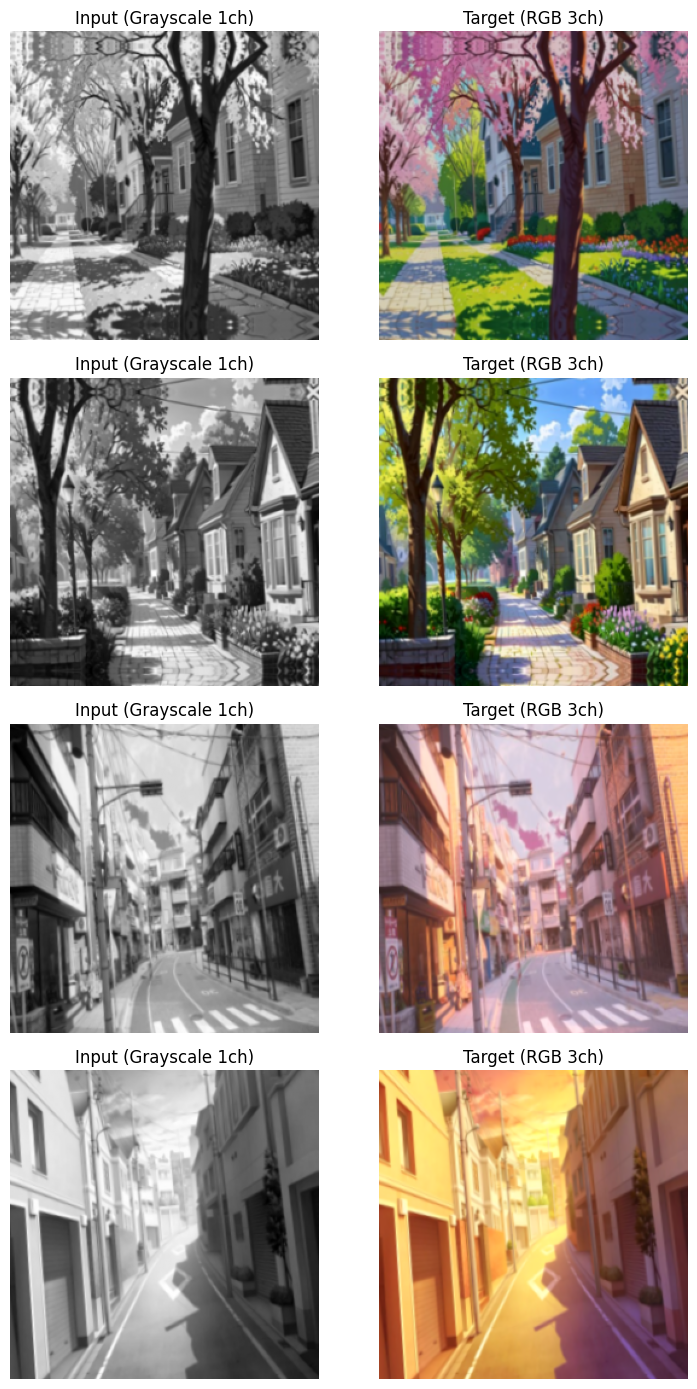

In [6]:
# Визуальная проверка обучающих пар (ЧБ вход и Цветной таргет)
for batch_gray, batch_color in train_data.take(1):
    fig, axes = plt.subplots(4, 2, figsize=(8, 14))
    for i in range(4):
        axes[i, 0].imshow(batch_gray[i, :, :, 0].numpy(), cmap="gray")
        axes[i, 0].set_title("Input (Grayscale 1ch)")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(batch_color[i].numpy())
        axes[i, 1].set_title("Target (RGB 3ch)")
        axes[i, 1].axis("off")
    plt.tight_layout()
    plt.show()

## 3. Архитектура модели (U-Net + MobileNetV2)

In [7]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

layer_names = [
    "block_1_expand_relu",
    "block_3_expand_relu",
    "block_6_expand_relu",
    "block_13_expand_relu",
    "block_16_project",
]

base_model_outputs = [base_model.get_layer(name).output for name in layer_names]

down_stack = tf.keras.Model(inputs=base_model.input, outputs=base_model_outputs)
down_stack.trainable = False


def upsample(filters, size):
    return tf.keras.Sequential([
        tf.keras.layers.Conv2DTranspose(
            filters,
            size,
            strides=2,
            padding="same",
            use_bias=False
        ),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.ReLU()
    ])


def build_model():
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1))

    # Дублируем 1 ЧБ-канал в 3 канала для предобученного MobileNetV2
    x_3ch = tf.keras.layers.Concatenate()([inputs, inputs, inputs])
    x = x_3ch * 2.0 - 1.0

    skips = down_stack(x)
    x = skips[-1]
    skips = reversed(skips[:-1])

    filters = [512, 256, 128, 64]

    for up, skip in zip([upsample(f, 4) for f in filters], skips):
        x = up(x)
        x = tf.keras.layers.Concatenate()([x, skip])

    x = upsample(32, 4)(x)
    # Приклеиваем исходный ЧБ-кадр перед выходом для сохранения четкости границ
    x = tf.keras.layers.Concatenate()([x, inputs])

    outputs = tf.keras.layers.Conv2D(
        3,
        kernel_size=3,
        padding="same",
        activation="sigmoid"
    )(x)

    return tf.keras.Model(inputs, outputs)


model = build_model()
print("input :", model.input_shape)
print("output:", model.output_shape)
model.summary()

/tmp/ipykernel_500/2080343767.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
input : (None, 256, 256, 1)
output: (None, 256, 256, 3)


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256, 256,  │          0 │ input_layer_2[0]… │
│ (Concatenate)       │ 3)                │            │ input_layer_2[0]… │
│                     │                   │            │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 256, 256,  │          0 │ concatenate[0][0] │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract (Subtract) │ (None, 256, 256,  │          0 │ multiply[0][0]    │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_1        │ [(None, 128, 128, │  1,841,984 │ subtract[0][0]    │
│ (Functional)        │ 96), (None, 64,   │            │                   │
│                     │ 64, 144), (None,  │            │                   │
│                     │ 32, 32, 192),     │            │                   │
│                     │ (None, 16, 16,    │            │                   │
│                     │ 576), (None, 8,   │            │                   │
│                     │ 8, 320)]          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 16, 16,    │  2,623,488 │ functional_1[0][… │
│ (Sequential)        │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 16, 16,    │          0 │ sequential_1[0][… │
│ (Concatenate)       │ 1088)             │            │ functional_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_2        │ (None, 32, 32,    │  4,457,472 │ concatenate_1[0]… │
│ (Sequential)        │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 32, 32,    │          0 │ sequential_2[0][… │
│ (Concatenate)       │ 448)              │            │ functional_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_3        │ (None, 64, 64,    │    918,016 │ concatenate_2[0]… │
│ (Sequential)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 64, 64,    │          0 │ sequential_3[0][… │
│ (Concatenate)       │ 272)              │            │ functional_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_4        │ (None, 128, 128,  │    278,784 │ concatenate_3[0]… │
│ (Sequential)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 128, 128,  │          0 │ sequential_4[0][… │
│ (Concatenate)       │ 160)              │            │ functional_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_5        │ (None, 256, 256,  │     82,048 │ concatenate_4[0]… │
│ (Sequential)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_5       │ (None, 256, 256,  │          0 │ sequential_5[0][

 Total params: 10,202,686 (38.92 MB)

 Trainable params: 8,358,718 (31.89 MB)

 Non-trainable params: 1,843,968 (7.03 MB)

## 4. Обучение декодера и Fine-Tuning энкодера

In [8]:
def colorization_loss(y_true, y_pred):
    mae = tf.reduce_mean(tf.abs(y_true - y_pred))
    ssim = 1.0 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    return 0.8 * mae + 0.2 * ssim


def psnr_metric(y_true, y_pred):
    return tf.image.psnr(y_true, y_pred, max_val=1.0)


model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=colorization_loss,
    metrics=["mae", psnr_metric],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_psnr_metric",
        mode="max",
        patience=12,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_psnr_metric",
        mode="max",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        BEST_MODEL_NAME,
        monitor="val_psnr_metric",
        mode="max",
        save_best_only=True,
        verbose=1,
    ),
]

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=60,
    callbacks=callbacks,
)

model.save(MODEL_NAME)

Epoch 1/60


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - loss: 0.3562 - mae: 0.2408 - psnr_metric: 10.6848  
Epoch 1: val_psnr_metric improved from None to 11.53267, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
4/4 ━━━━━━━━━━━━━━━━━━━━ 101s 12s/step - loss: 0.3562 - mae: 0.2408 - psnr_metric: 10.6848 - val_loss: 0.3038 - val_mae: 0.2124 - val_psnr_metric: 11.5327 - learning_rate: 0.0010
Epoch 2/60
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 282ms/step - loss: 0.2502 - mae: 0.1871 - psnr_metric: 12.8785
Epoch 2: val_psnr_metric improved from 11.53267 to 13.88657, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 622ms/step - loss: 0.2502 - mae: 0.1871 - psnr_metric: 12.8785 - val_loss: 0.2376 - val_mae: 0.1623 - val_psnr_metric: 13.8866 - learning_rate: 0.0010
Epoch 3/60
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step - loss: 0.1850 - mae: 0.1421 - psnr_metric: 15.1628
Epoch 3: val_psnr_metric improved from 13.88657 to 14.45810

In [9]:
FINE_TUNE = True

if FINE_TUNE:
    down_stack.trainable = True
    fine_tune_from = "block_10_expand"
    trainable_flag = False

    for layer in down_stack.layers:
        if layer.name == fine_tune_from:
            trainable_flag = True
        layer.trainable = trainable_flag and not isinstance(
            layer, tf.keras.layers.BatchNormalization
        )

    print("Обучаемых параметров:", sum(int(tf.size(w)) for w in model.trainable_weights))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=2e-5),
        loss=colorization_loss,
        metrics=["mae", psnr_metric],
    )

    callbacks_fine = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_psnr_metric",
            mode="max",
            patience=10,
            restore_best_weights=True,
            verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_psnr_metric",
            mode="max",
            factor=0.5,
            patience=3,
            min_lr=1e-7,
            verbose=1,
        ),
        tf.keras.callbacks.ModelCheckpoint(
            BEST_MODEL_NAME,
            monitor="val_psnr_metric",
            mode="max",
            save_best_only=True,
            verbose=1,
        ),
    ]

    history_fine = model.fit(
        train_data,
        validation_data=val_data,
        epochs=40,
        callbacks=callbacks_fine,
    )

    model.save(MODEL_NAME)

Обучаемых параметров: 9908926
Epoch 1/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - loss: 0.0964 - mae: 0.0811 - psnr_metric: 19.5813   
Epoch 1: val_psnr_metric improved from None to 19.03766, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
4/4 ━━━━━━━━━━━━━━━━━━━━ 44s 6s/step - loss: 0.0964 - mae: 0.0811 - psnr_metric: 19.5813 - val_loss: 0.0997 - val_mae: 0.0834 - val_psnr_metric: 19.0377 - learning_rate: 2.0000e-05
Epoch 2/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 385ms/step - loss: 0.0933 - mae: 0.0790 - psnr_metric: 19.7726
Epoch 2: val_psnr_metric did not improve from 19.03766
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 448ms/step - loss: 0.0933 - mae: 0.0790 - psnr_metric: 19.7726 - val_loss: 0.0999 - val_mae: 0.0836 - val_psnr_metric: 19.0108 - learning_rate: 2.0000e-05
Epoch 3/40
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step - loss: 0.0962 - mae: 0.0809 - psnr_metric: 19.5232
Epoch 3: val_psnr_metric did not improve from 19.03766
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 331ms/step - loss: 0

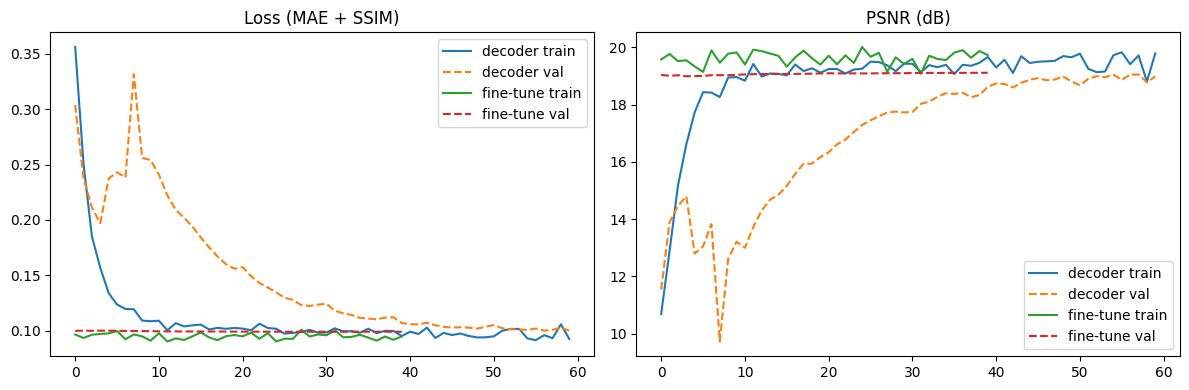

In [10]:
def plot_history(histories, labels):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    for h, label in zip(histories, labels):
        plt.plot(h.history["loss"], label=f"{label} train")
        plt.plot(h.history["val_loss"], "--", label=f"{label} val")
    plt.title("Loss (MAE + SSIM)")
    plt.legend()

    plt.subplot(1, 2, 2)
    for h, label in zip(histories, labels):
        plt.plot(h.history["psnr_metric"], label=f"{label} train")
        plt.plot(h.history["val_psnr_metric"], "--", label=f"{label} val")
    plt.title("PSNR (dB)")
    plt.legend()

    plt.tight_layout()
    plt.show()


histories = [history]
labels = ["decoder"]

if "history_fine" in dir():
    histories.append(history_fine)
    labels.append("fine-tune")

plot_history(histories, labels)

## 5. Проверка результатов и экспорт в ONNX

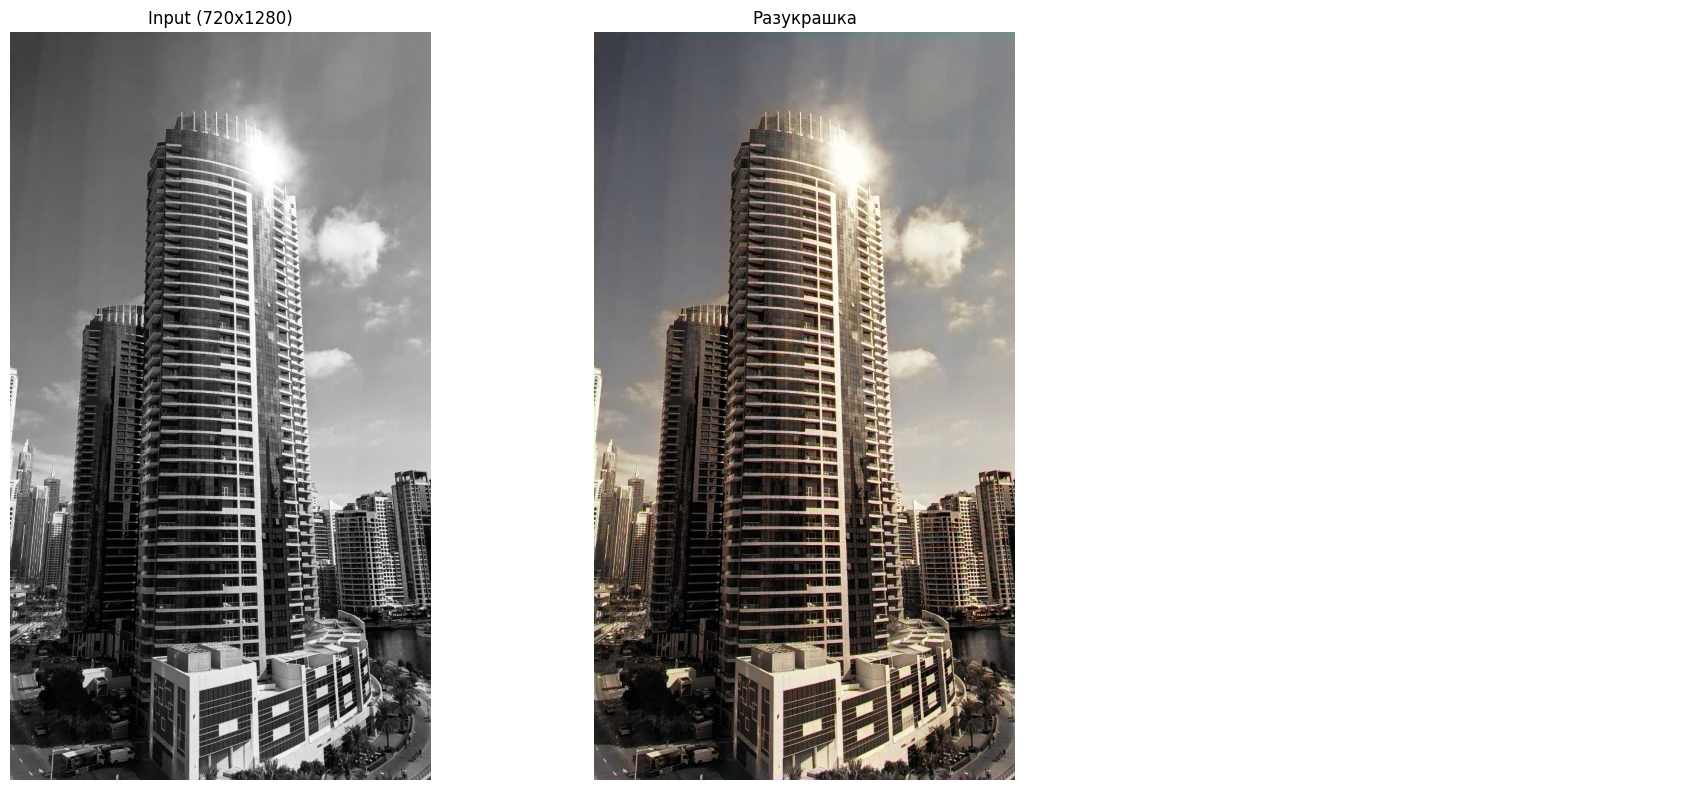

In [15]:
def predict_image_hd(image_path):
    original = tf.keras.utils.load_img(image_path)
    original_np = np.array(original.convert("RGB"), dtype=np.float32) / 255.0
    h, w, _ = original_np.shape

    gray_full = tf.image.rgb_to_grayscale(original_np)

    gray_resized = tf.image.resize(gray_full, [IMG_SIZE, IMG_SIZE])
    pred_rgb_small = model.predict(gray_resized[None, ...], verbose=0)[0]

    pred_rgb_full = tf.image.resize(pred_rgb_small, [h, w], method="bicubic")
    pred_rgb_full = tf.clip_by_value(pred_rgb_full, 0.0, 1.0)

    pred_yuv = tf.image.rgb_to_yuv(pred_rgb_full)
    uv_channels = pred_yuv[:, :, 1:]

    sharp_yuv = tf.concat([gray_full, uv_channels], axis=-1)
    sharp_rgb = tf.image.yuv_to_rgb(sharp_yuv)
    sharp_rgb = tf.clip_by_value(sharp_rgb, 0.0, 1.0).numpy()

    fig, axes = plt.subplots(1, 3, figsize=(18, 8))
    axes[0].imshow(gray_full[:, :, 0], cmap="gray")
    axes[0].set_title(f"Input ({w}x{h})")

    axes[1].imshow(sharp_rgb)
    axes[1].set_title("Разукрашка")

    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

from google.colab import files

upload = files.upload()

filename = next(iter(upload))

predict_image_hd(filename)


In [16]:
import keras
import tf2onnx
import onnx
import onnxruntime as ort

export_model = keras.models.load_model(
    BEST_MODEL_NAME if os.path.exists(BEST_MODEL_NAME) else MODEL_NAME,
    compile=False
)

spec = (tf.TensorSpec((None, IMG_SIZE, IMG_SIZE, 1), tf.float32, name="input"),)
onnx_model, _ = tf2onnx.convert.from_keras(export_model, input_signature=spec, opset=13)
onnx.save_model(onnx_model, ONNX_NAME)
print(f"ONNX сохранён: {ONNX_NAME}")
sess = ort.InferenceSession(ONNX_NAME, providers=["CPUExecutionProvider"])
inp, out = sess.get_inputs()[0], sess.get_outputs()[0]
print("ONNX input :", inp.name, inp.shape)
print("ONNX output:", out.name, out.shape)

xb, _ = next(iter(val_data))
x = xb[:4].numpy()
keras_pred = export_model.predict(x, verbose=0)
onnx_pred = sess.run(None, {inp.name: x})[0]
print("Max abs diff Keras vs ONNX:", float(np.abs(keras_pred - onnx_pred).max()))

ONNX сохранён: model.onnx
ONNX input : input ['unk__873', 256, 256, 1]
ONNX output: conv2d ['unk__874', 256, 256, 3]
Max abs diff Keras vs ONNX: 9.238719940185547e-07


In [17]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/Colorization/
!cp best_model.keras model.keras model.onnx /content/drive/MyDrive/Colorization/

Mounted at /content/drive
